# Calculate Energy density on target by finding ratio of ablated target to intact target
Energy density on target is proportional to the area ablated by the pump pulse. 
Using pre and post images of the target with a diode backlight, we can calculate the ablated area.

Processing: First we correct images by subtracting the average background value. 

Finding area: Then we count the number of pixels greater than a threshold value.

We compare the average ablated area to the imaged area when there is no target. 

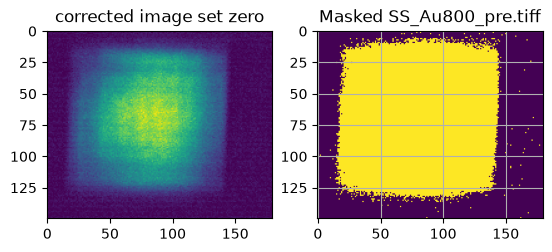

pre:  290865755.7823 15261


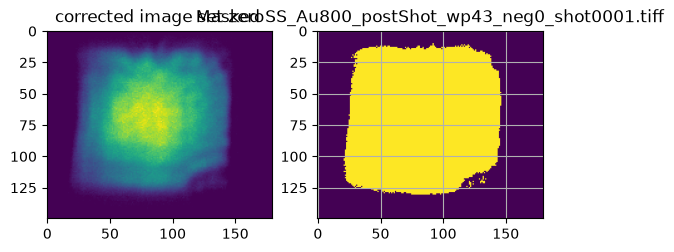

neg0 388455006.78879994 13216


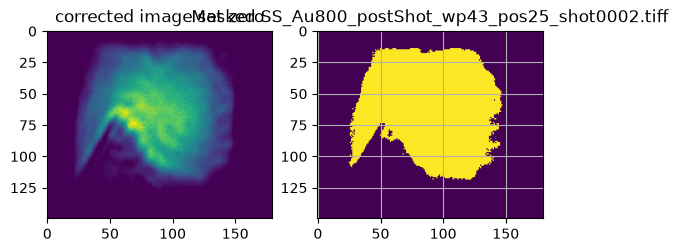

pos25 149203068.6139 9473
neg0/pre: 1.3355130298650253
pos25/pre: 0.5129619614815428
pos25/neg0: 0.38409356555164853
Areas
neg0/pre: 0.8659982963108578
pos25/pre: 0.620732586331171
pos25/neg0: 0.7167826876513317


'#plt.hist(imgCorr.ravel(), bins=256)\nplt.title("Corrected Image Histogram")\nplt.xlabel("Pixel value")\nplt.ylabel("Count")\n_, imgThres = cv.threshold(..., 10, 255, cv.THRESH_BINARY)'

In [ ]:
import cv2 as cv
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np
import os
from myfuncs.utility import hist
%matplotlib inline

wv = "800nm"
root = f'/Users/yuewang/SLAC/goldthz/Au_data/{wv}/images/'

preImgPath = os.path.join(root, "SS_Au800_pre.tiff")
preImg = np.array(Image.open(preImgPath))
bg = np.mean(preImg[0:100, 0:100])
bgStd = np.std(preImg[0:100, 0:100])
cropBox = (760, 300, 940, 450)

def bg_corr(imgName):
    num = 2
    if imgName == "SS_Au800_pre.tiff":
        num = 0
    threshold = bg + num*bgStd

    imgPath = os.path.join(root, imgName)
    img1 = (Image.open(imgPath)).crop(cropBox)
    img = np.array(img1)
    plt.figure()
    imgCorr = img - bg
    imgCorr[imgCorr < 0] = 0
    plt.subplot(121)
    plt.imshow(imgCorr)
    plt.title("corrected image set zero")
    mask = imgCorr > threshold
    plt.subplot(122)
    plt.imshow(mask)
    plt.title("Masked " + imgName)
    
    plt.grid(axis='both', ls='-')
    plt.show()

    return (img1, imgCorr[mask])
def window():
    wPath = "07202026_pump_with_window.tiff"
    _, windCorr = bg_corr(wPath)
    nwPath = "07202026_pump_no_window.tiff"
    _, nwCorr = bg_corr(nwPath)
    beamSumWindow = np.sum(windCorr)
    beamSumNW = np.sum(nwCorr)

    T = beamSumWindow/beamSumNW
    print("window", beamSumWindow)
    print("no window", beamSumNW)
    print(T)

_, array = bg_corr("SS_Au800_pre.tiff")
sum1 = np.sum(array)
preArea = cv.countNonZero(array)
print("pre: ", sum1, preArea)
_, array = bg_corr("SS_Au800_postShot_wp43_neg0_shot0001.tiff")
sum = np.sum(array)
neg0Area = cv.countNonZero(array)

print("neg0", sum, neg0Area)
_, array = bg_corr("SS_Au800_postShot_wp43_pos25_shot0002.tiff")
sum3 = np.sum(array)
pos25Area = cv.countNonZero(array)


"""#plt.hist(imgCorr.ravel(), bins=256)
plt.title("Corrected Image Histogram")
plt.xlabel("Pixel value")
plt.ylabel("Count")
_, imgThres = cv.threshold(..., 10, 255, cv.THRESH_BINARY)"""


# Calculate area of each shot

--------------------------------
File path: /Users/yuewang/SLAC/goldthz/Au_data/800nm/images/SS_Au800_postShot_wp43_neg0_shot0001.tiff
creating plot for file: /Users/yuewang/SLAC/goldthz/Au_data/800nm/images/SS_Au800_postShot_wp43_neg0_shot0001.tiff


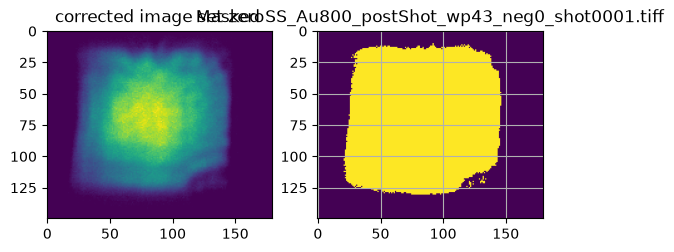

area 13216
--------------------------------
File path: /Users/yuewang/SLAC/goldthz/Au_data/800nm/images/SS_Au800_postShot_wp43_neg0_shot0002.tiff
creating plot for file: /Users/yuewang/SLAC/goldthz/Au_data/800nm/images/SS_Au800_postShot_wp43_neg0_shot0002.tiff


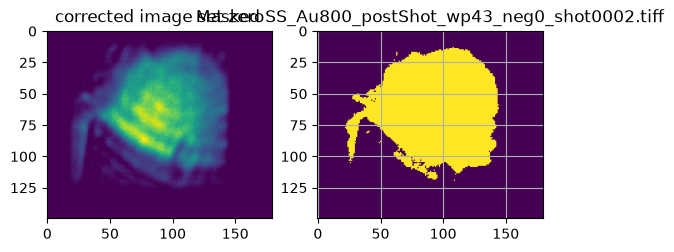

area 8331
--------------------------------
File path: /Users/yuewang/SLAC/goldthz/Au_data/800nm/images/SS_Au800_postShot_wp43_neg0_shot0003.tiff
creating plot for file: /Users/yuewang/SLAC/goldthz/Au_data/800nm/images/SS_Au800_postShot_wp43_neg0_shot0003.tiff


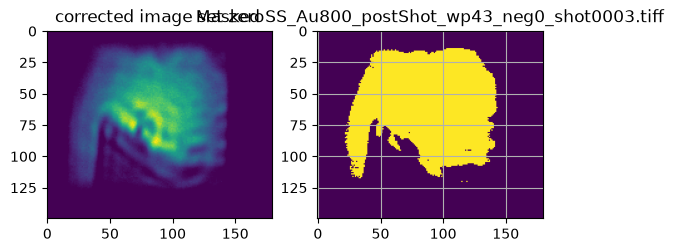

area 9084
--------------------------------
File path: /Users/yuewang/SLAC/goldthz/Au_data/800nm/images/SS_Au800_postShot_wp43_neg1_shot0001.tiff
creating plot for file: /Users/yuewang/SLAC/goldthz/Au_data/800nm/images/SS_Au800_postShot_wp43_neg1_shot0001.tiff


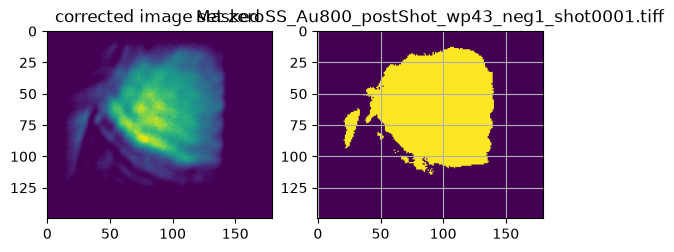

area 7682
--------------------------------
File path: /Users/yuewang/SLAC/goldthz/Au_data/800nm/images/SS_Au800_postShot_wp43_neg1_shot0002.tiff
creating plot for file: /Users/yuewang/SLAC/goldthz/Au_data/800nm/images/SS_Au800_postShot_wp43_neg1_shot0002.tiff


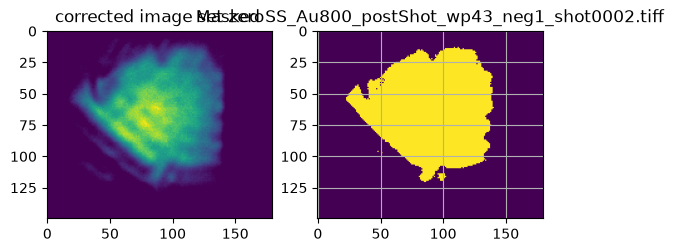

area 8107
--------------------------------
File path: /Users/yuewang/SLAC/goldthz/Au_data/800nm/images/SS_Au800_postShot_wp43_neg1_shot0003.tiff
creating plot for file: /Users/yuewang/SLAC/goldthz/Au_data/800nm/images/SS_Au800_postShot_wp43_neg1_shot0003.tiff


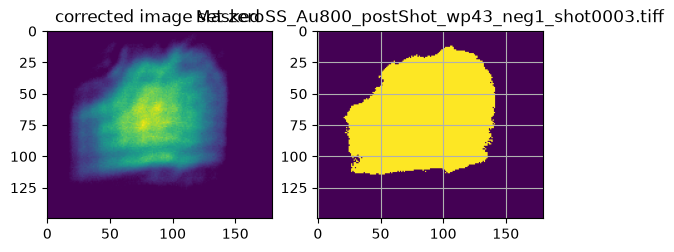

area 9363
--------------------------------
File path: /Users/yuewang/SLAC/goldthz/Au_data/800nm/images/SS_Au800_postShot_wp43_neg2_shot0001.tiff
creating plot for file: /Users/yuewang/SLAC/goldthz/Au_data/800nm/images/SS_Au800_postShot_wp43_neg2_shot0001.tiff


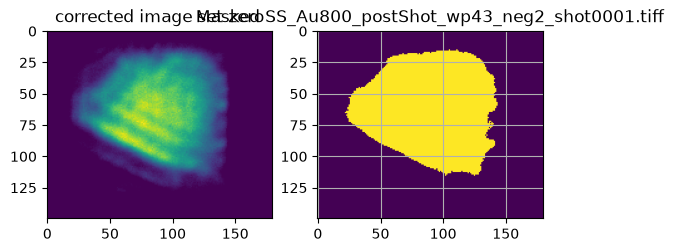

area 8658
--------------------------------
File path: /Users/yuewang/SLAC/goldthz/Au_data/800nm/images/SS_Au800_postShot_wp43_neg2_shot0002.tiff
creating plot for file: /Users/yuewang/SLAC/goldthz/Au_data/800nm/images/SS_Au800_postShot_wp43_neg2_shot0002.tiff


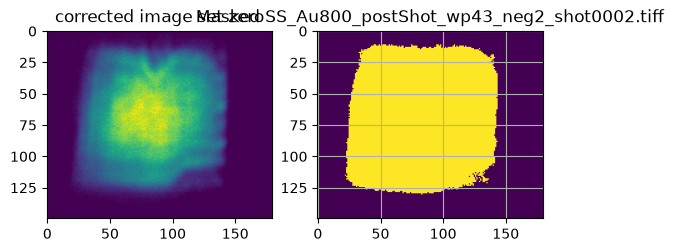

area 12911
--------------------------------
File path: /Users/yuewang/SLAC/goldthz/Au_data/800nm/images/SS_Au800_postShot_wp43_neg2_shot0003.tiff
creating plot for file: /Users/yuewang/SLAC/goldthz/Au_data/800nm/images/SS_Au800_postShot_wp43_neg2_shot0003.tiff


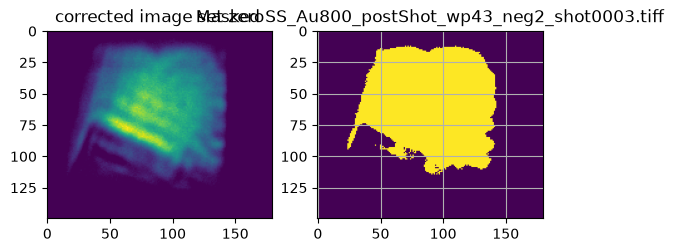

area 8806
--------------------------------
File path: /Users/yuewang/SLAC/goldthz/Au_data/800nm/images/SS_Au800_postShot_wp43_pos1_shot0001.tiff
creating plot for file: /Users/yuewang/SLAC/goldthz/Au_data/800nm/images/SS_Au800_postShot_wp43_pos1_shot0001.tiff


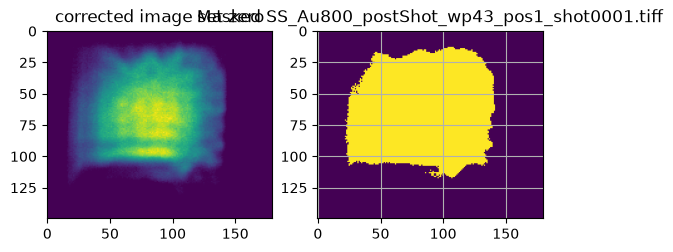

area 9921
--------------------------------
File path: /Users/yuewang/SLAC/goldthz/Au_data/800nm/images/SS_Au800_postShot_wp43_pos1_shot0002.tiff
File path does not exist: /Users/yuewang/SLAC/goldthz/Au_data/800nm/images/SS_Au800_postShot_wp43_pos1_shot0002.tiff
--------------------------------
File path: /Users/yuewang/SLAC/goldthz/Au_data/800nm/images/SS_Au800_postShot_wp43_pos1_shot0003.tiff
creating plot for file: /Users/yuewang/SLAC/goldthz/Au_data/800nm/images/SS_Au800_postShot_wp43_pos1_shot0003.tiff


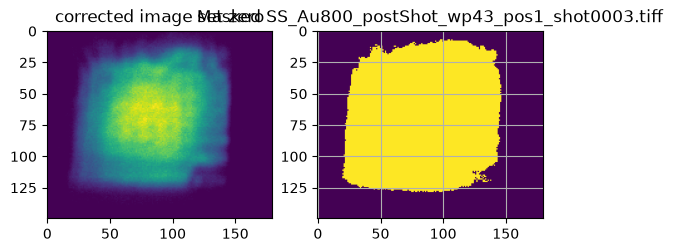

area 13372
--------------------------------
File path: /Users/yuewang/SLAC/goldthz/Au_data/800nm/images/SS_Au800_postShot_wp43_pos2_shot0001.tiff
creating plot for file: /Users/yuewang/SLAC/goldthz/Au_data/800nm/images/SS_Au800_postShot_wp43_pos2_shot0001.tiff


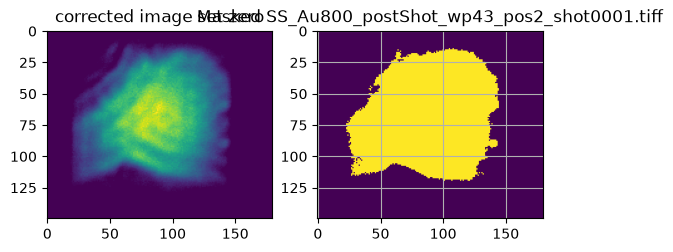

area 9710
--------------------------------
File path: /Users/yuewang/SLAC/goldthz/Au_data/800nm/images/SS_Au800_postShot_wp43_pos2_shot0002.tiff
creating plot for file: /Users/yuewang/SLAC/goldthz/Au_data/800nm/images/SS_Au800_postShot_wp43_pos2_shot0002.tiff


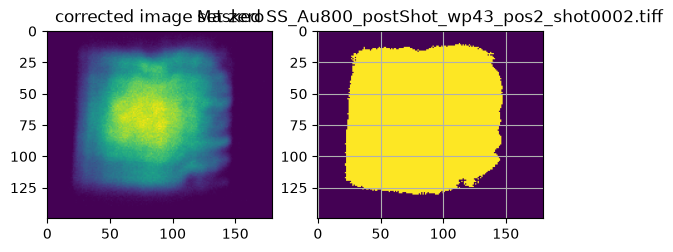

area 13305
--------------------------------
File path: /Users/yuewang/SLAC/goldthz/Au_data/800nm/images/SS_Au800_postShot_wp43_pos2_shot0003.tiff
creating plot for file: /Users/yuewang/SLAC/goldthz/Au_data/800nm/images/SS_Au800_postShot_wp43_pos2_shot0003.tiff


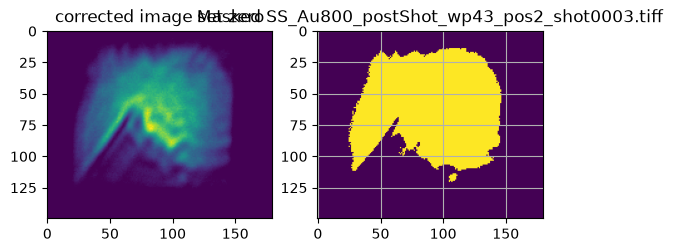

area 9128
--------------------------------
File path: /Users/yuewang/SLAC/goldthz/Au_data/800nm/images/SS_Au800_postShot_wp43_pos5_shot0001.tiff
creating plot for file: /Users/yuewang/SLAC/goldthz/Au_data/800nm/images/SS_Au800_postShot_wp43_pos5_shot0001.tiff


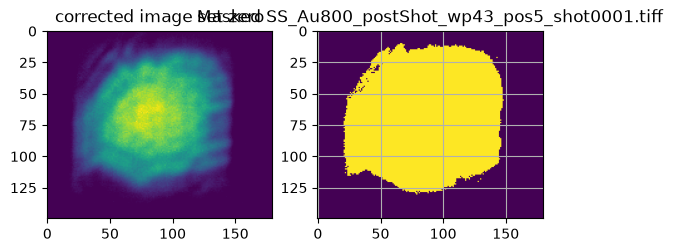

area 12351
--------------------------------
File path: /Users/yuewang/SLAC/goldthz/Au_data/800nm/images/SS_Au800_postShot_wp43_pos5_shot0002.tiff
creating plot for file: /Users/yuewang/SLAC/goldthz/Au_data/800nm/images/SS_Au800_postShot_wp43_pos5_shot0002.tiff


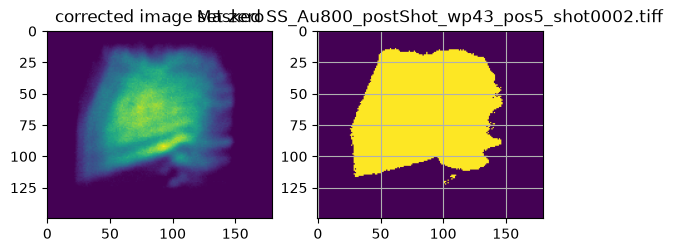

area 9687
--------------------------------
File path: /Users/yuewang/SLAC/goldthz/Au_data/800nm/images/SS_Au800_postShot_wp43_pos5_shot0003.tiff
creating plot for file: /Users/yuewang/SLAC/goldthz/Au_data/800nm/images/SS_Au800_postShot_wp43_pos5_shot0003.tiff


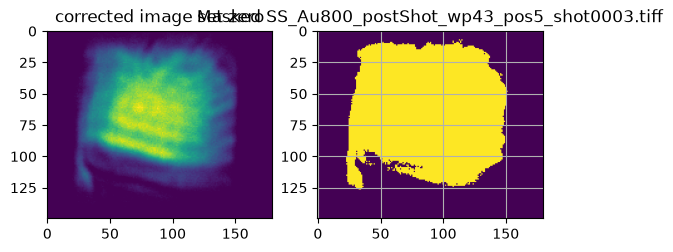

area 12127
--------------------------------
File path: /Users/yuewang/SLAC/goldthz/Au_data/800nm/images/SS_Au800_postShot_wp43_pos7p5_shot0001.tiff
creating plot for file: /Users/yuewang/SLAC/goldthz/Au_data/800nm/images/SS_Au800_postShot_wp43_pos7p5_shot0001.tiff


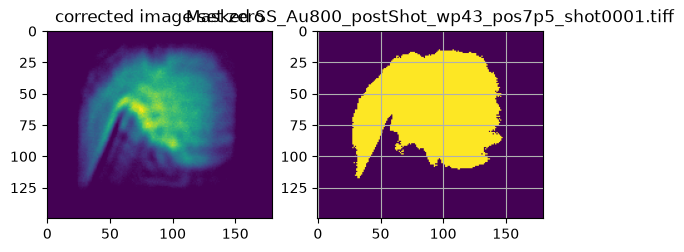

area 8420
--------------------------------
File path: /Users/yuewang/SLAC/goldthz/Au_data/800nm/images/SS_Au800_postShot_wp43_pos7p5_shot0002.tiff
creating plot for file: /Users/yuewang/SLAC/goldthz/Au_data/800nm/images/SS_Au800_postShot_wp43_pos7p5_shot0002.tiff


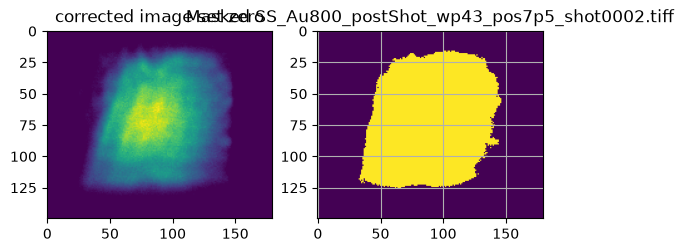

area 9781
--------------------------------
File path: /Users/yuewang/SLAC/goldthz/Au_data/800nm/images/SS_Au800_postShot_wp43_pos7p5_shot0003.tiff
creating plot for file: /Users/yuewang/SLAC/goldthz/Au_data/800nm/images/SS_Au800_postShot_wp43_pos7p5_shot0003.tiff


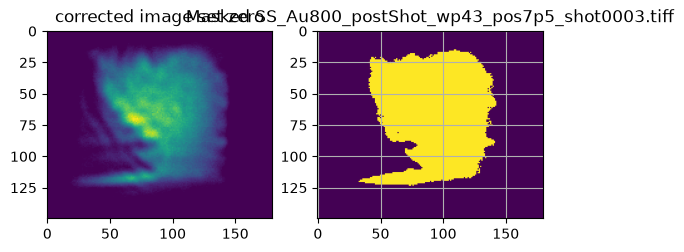

area 8257
--------------------------------
File path: /Users/yuewang/SLAC/goldthz/Au_data/800nm/images/SS_Au800_postShot_wp43_pos10_shot0001.tiff
File path does not exist: /Users/yuewang/SLAC/goldthz/Au_data/800nm/images/SS_Au800_postShot_wp43_pos10_shot0001.tiff
--------------------------------
File path: /Users/yuewang/SLAC/goldthz/Au_data/800nm/images/SS_Au800_postShot_wp43_pos10_shot0002.tiff
File path does not exist: /Users/yuewang/SLAC/goldthz/Au_data/800nm/images/SS_Au800_postShot_wp43_pos10_shot0002.tiff
--------------------------------
File path: /Users/yuewang/SLAC/goldthz/Au_data/800nm/images/SS_Au800_postShot_wp43_pos10_shot0003.tiff
creating plot for file: /Users/yuewang/SLAC/goldthz/Au_data/800nm/images/SS_Au800_postShot_wp43_pos10_shot0003.tiff


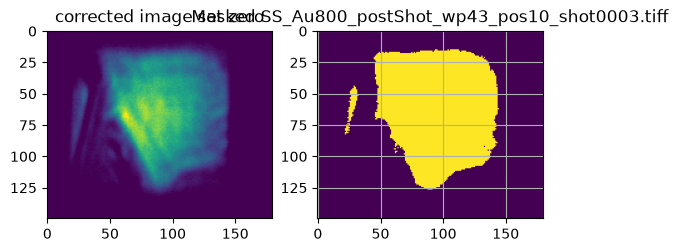

area 8594
--------------------------------
File path: /Users/yuewang/SLAC/goldthz/Au_data/800nm/images/SS_Au800_postShot_wp43_pos12_shot0001.tiff
creating plot for file: /Users/yuewang/SLAC/goldthz/Au_data/800nm/images/SS_Au800_postShot_wp43_pos12_shot0001.tiff


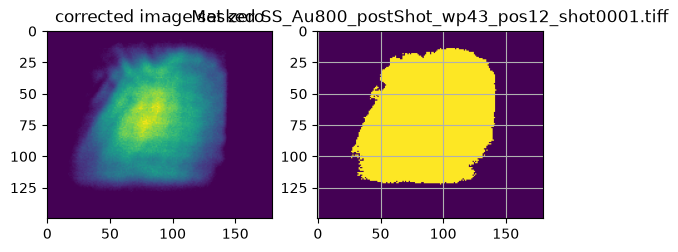

area 9800
--------------------------------
File path: /Users/yuewang/SLAC/goldthz/Au_data/800nm/images/SS_Au800_postShot_wp43_pos12_shot0002.tiff
creating plot for file: /Users/yuewang/SLAC/goldthz/Au_data/800nm/images/SS_Au800_postShot_wp43_pos12_shot0002.tiff


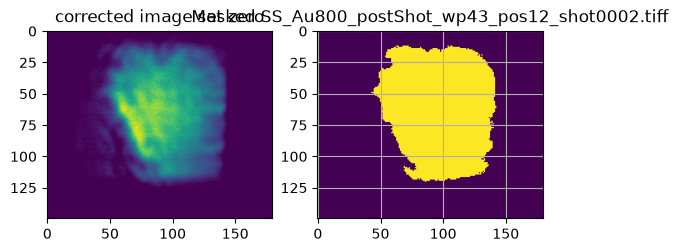

area 8261
--------------------------------
File path: /Users/yuewang/SLAC/goldthz/Au_data/800nm/images/SS_Au800_postShot_wp43_pos12_shot0003.tiff
creating plot for file: /Users/yuewang/SLAC/goldthz/Au_data/800nm/images/SS_Au800_postShot_wp43_pos12_shot0003.tiff


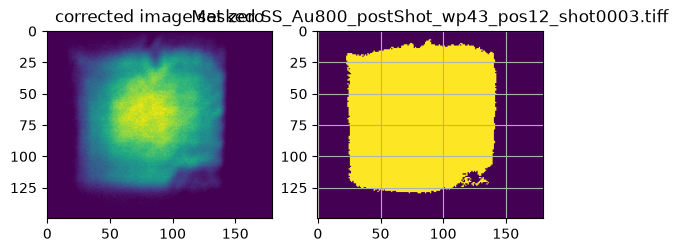

area 12830
--------------------------------
File path: /Users/yuewang/SLAC/goldthz/Au_data/800nm/images/SS_Au800_postShot_wp43_pos15_shot0001.tiff
creating plot for file: /Users/yuewang/SLAC/goldthz/Au_data/800nm/images/SS_Au800_postShot_wp43_pos15_shot0001.tiff


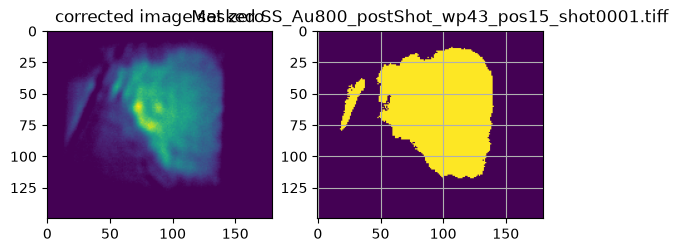

area 7491
--------------------------------
File path: /Users/yuewang/SLAC/goldthz/Au_data/800nm/images/SS_Au800_postShot_wp43_pos15_shot0002.tiff
creating plot for file: /Users/yuewang/SLAC/goldthz/Au_data/800nm/images/SS_Au800_postShot_wp43_pos15_shot0002.tiff


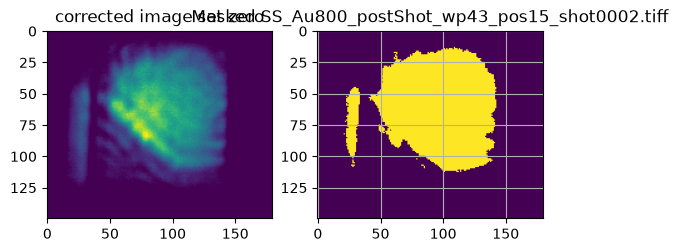

area 7829
--------------------------------
File path: /Users/yuewang/SLAC/goldthz/Au_data/800nm/images/SS_Au800_postShot_wp43_pos15_shot0003.tiff
creating plot for file: /Users/yuewang/SLAC/goldthz/Au_data/800nm/images/SS_Au800_postShot_wp43_pos15_shot0003.tiff


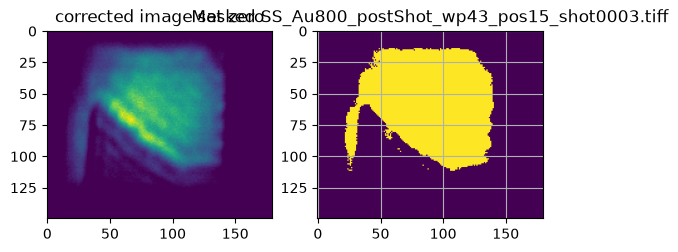

area 8274
--------------------------------
File path: /Users/yuewang/SLAC/goldthz/Au_data/800nm/images/SS_Au800_postShot_wp43_pos20_shot0001.tiff
creating plot for file: /Users/yuewang/SLAC/goldthz/Au_data/800nm/images/SS_Au800_postShot_wp43_pos20_shot0001.tiff


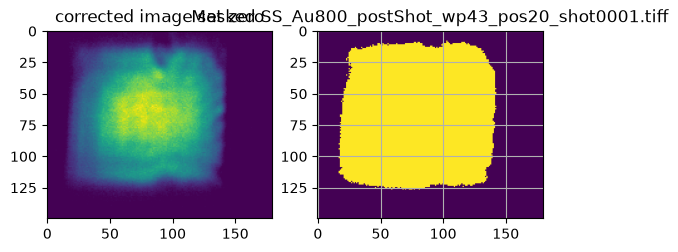

area 13285
--------------------------------
File path: /Users/yuewang/SLAC/goldthz/Au_data/800nm/images/SS_Au800_postShot_wp43_pos20_shot0002.tiff
creating plot for file: /Users/yuewang/SLAC/goldthz/Au_data/800nm/images/SS_Au800_postShot_wp43_pos20_shot0002.tiff


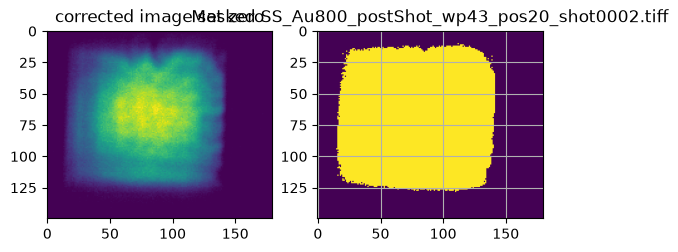

area 13477
--------------------------------
File path: /Users/yuewang/SLAC/goldthz/Au_data/800nm/images/SS_Au800_postShot_wp43_pos20_shot0003.tiff
creating plot for file: /Users/yuewang/SLAC/goldthz/Au_data/800nm/images/SS_Au800_postShot_wp43_pos20_shot0003.tiff


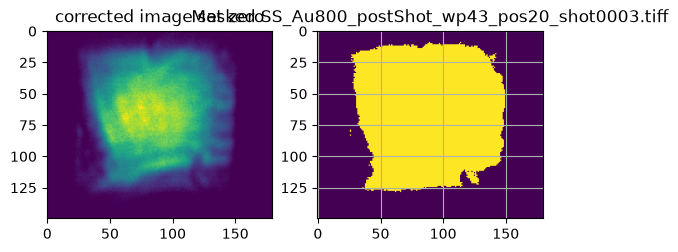

area 12208
--------------------------------
File path: /Users/yuewang/SLAC/goldthz/Au_data/800nm/images/SS_Au800_postShot_wp43_pos25_shot0001.tiff
creating plot for file: /Users/yuewang/SLAC/goldthz/Au_data/800nm/images/SS_Au800_postShot_wp43_pos25_shot0001.tiff


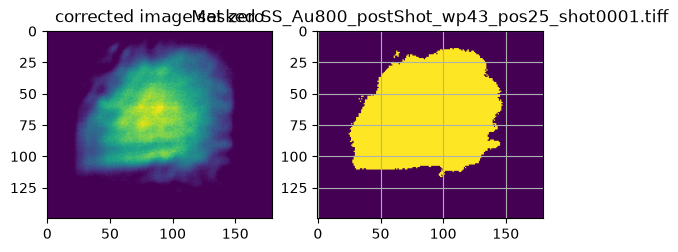

area 9182
--------------------------------
File path: /Users/yuewang/SLAC/goldthz/Au_data/800nm/images/SS_Au800_postShot_wp43_pos25_shot0002.tiff
creating plot for file: /Users/yuewang/SLAC/goldthz/Au_data/800nm/images/SS_Au800_postShot_wp43_pos25_shot0002.tiff


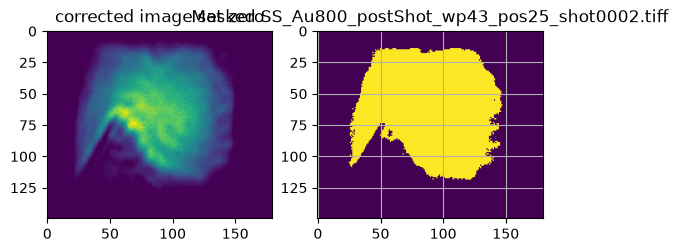

area 9473
--------------------------------
File path: /Users/yuewang/SLAC/goldthz/Au_data/800nm/images/SS_Au800_postShot_wp43_pos25_shot0003.tiff
creating plot for file: /Users/yuewang/SLAC/goldthz/Au_data/800nm/images/SS_Au800_postShot_wp43_pos25_shot0003.tiff


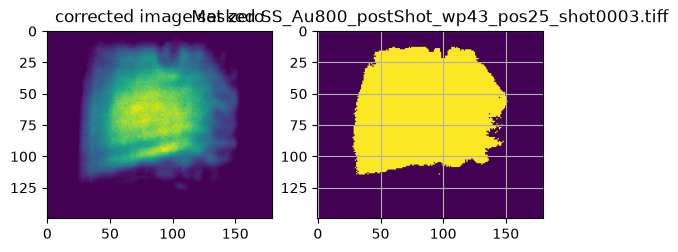

area 9970
--------------------------------
File path: /Users/yuewang/SLAC/goldthz/Au_data/800nm/images/SS_Au800_postShot_wp43_pos30_shot0001.tiff
creating plot for file: /Users/yuewang/SLAC/goldthz/Au_data/800nm/images/SS_Au800_postShot_wp43_pos30_shot0001.tiff


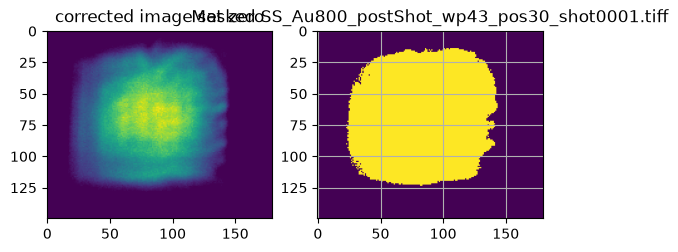

area 11036
--------------------------------
File path: /Users/yuewang/SLAC/goldthz/Au_data/800nm/images/SS_Au800_postShot_wp43_pos30_shot0002.tiff
creating plot for file: /Users/yuewang/SLAC/goldthz/Au_data/800nm/images/SS_Au800_postShot_wp43_pos30_shot0002.tiff


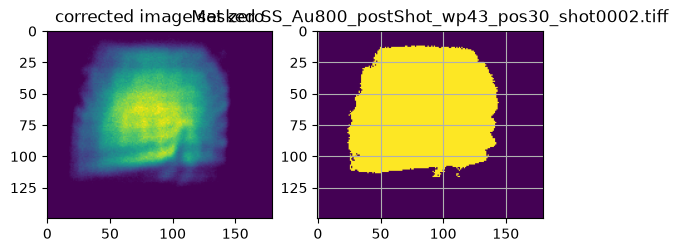

area 10346
--------------------------------
File path: /Users/yuewang/SLAC/goldthz/Au_data/800nm/images/SS_Au800_postShot_wp43_pos30_shot0003.tiff
creating plot for file: /Users/yuewang/SLAC/goldthz/Au_data/800nm/images/SS_Au800_postShot_wp43_pos30_shot0003.tiff


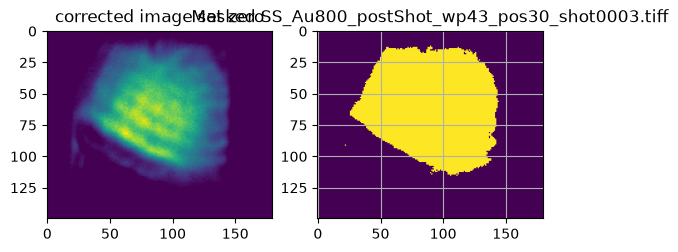

area 8827
--------------------------------
File path: /Users/yuewang/SLAC/goldthz/Au_data/800nm/images/SS_Au800_postShot_wp43_pos50_shot0001.tiff
creating plot for file: /Users/yuewang/SLAC/goldthz/Au_data/800nm/images/SS_Au800_postShot_wp43_pos50_shot0001.tiff


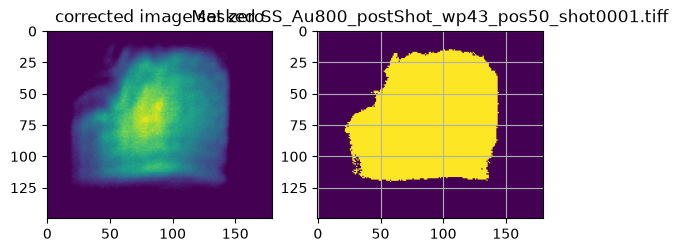

area 10207
--------------------------------
File path: /Users/yuewang/SLAC/goldthz/Au_data/800nm/images/SS_Au800_postShot_wp43_pos50_shot0002.tiff
creating plot for file: /Users/yuewang/SLAC/goldthz/Au_data/800nm/images/SS_Au800_postShot_wp43_pos50_shot0002.tiff


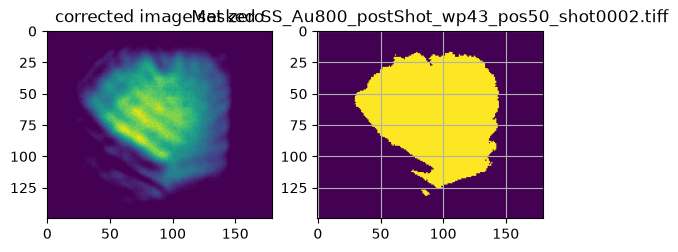

area 8511
--------------------------------
File path: /Users/yuewang/SLAC/goldthz/Au_data/800nm/images/SS_Au800_postShot_wp43_pos50_shot0003.tiff
File path does not exist: /Users/yuewang/SLAC/goldthz/Au_data/800nm/images/SS_Au800_postShot_wp43_pos50_shot0003.tiff


In [56]:
from pprint import pprint
areas = []
def cycle_through(file_root: str, position: str, p_range: list, wp: str, func):
    for digit in p_range:
        pos = position + str(digit)

        shot_num = 3
        for shot in range(shot_num):
            num = '{:0>4}'.format(int(shot + 1))
            imgName = 'SS_Au800_postShot_' + wp + '_' + pos + '_shot' + num + ".tiff" 
            file_path = file_root + imgName

            print("--------------------------------")
            print(f"File path: {file_path}")
            if not os.path.exists(file_path):
                print(f"File path does not exist: {file_path}")
                continue
            else:
                print(f"creating plot for file: {file_path}")
                _, img = func(imgName)
                area = cv.countNonZero(img)
                print("area", area)
                areas.append(area)


cycle_through(root, "neg", [i for i in range(3)], wp="wp43", func=bg_corr)
cycle_through(root, "pos", [1, 2, 5, '7p5', 10, 12, 15, 20, 25, 30, 50], wp="wp43", func=bg_corr)

## mean area and std dev

In [57]:
areaMean = np.mean(areas)
areaStd = np.std(areas)
print(f"mean: {areaMean}, std: {areaStd}")

print(f"OG window area: {preArea}")

# average ratio of transmitted laser energy U
meanRatio = areaMean/preArea
stdRatio = areaStd/preArea
print(f"For Ratio: mean: {meanRatio}, std: {stdRatio}")

mean: 10047.842105263158, std: 1880.571994819882
OG window area: 15261
For Ratio: mean: 0.6583999806869247, std: 0.12322731110804548
